# Листок № 2: решения по отдельным заданиям

Каждый пункт 2.1-2.10 расположен в отдельном блоке. Оба задания с номером 2.10 сохранены отдельно.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display
sp.init_printing()


## 2.1

In [2]:
import sympy as sp
from IPython.display import display
sp.init_printing()

# 2.1: алгебраическая, тригонометрическая и показательная формы.
expressions = [
    (5 + sp.I)*(7 - 6*sp.I)/(3 + sp.I),
    (1 + sp.I)**5/(1 - sp.I)**3,
    (-1 + sp.I*sp.sqrt(3))**15/(1 - sp.I)**20
    + (-1 - sp.I*sp.sqrt(3))**15/(1 + sp.I)**20
]
for label, expression in zip('abc', expressions):
    z = sp.simplify(sp.expand_complex(expression))
    r, phi = sp.simplify(sp.Abs(z)), sp.arg(z)
    print(f'2.1({label}):')
    print('Алгебраическая форма:'); display(z)
    print('Модуль и главный аргумент:'); display((r, phi))
    print(f'Тригонометрическая: ({r})*(cos({phi}) + i*sin({phi}))')
    print(f'Показательная: ({r})*exp(i*({phi}))')
    print()


2.1(a):
Алгебраическая форма:


Модуль и главный аргумент:


Тригонометрическая: (sqrt(221))*(cos(-atan(11/10)) + i*sin(-atan(11/10)))
Показательная: (sqrt(221))*exp(i*(-atan(11/10)))

2.1(b):
Алгебраическая форма:


Модуль и главный аргумент:


Тригонометрическая: (2)*(cos(0) + i*sin(0))
Показательная: (2)*exp(i*(0))

2.1(c):
Алгебраическая форма:


Модуль и главный аргумент:


Тригонометрическая: (64)*(cos(pi) + i*sin(pi))
Показательная: (64)*exp(i*(pi))



## 2.2

2.2: z_k =


k = 0, 1, ..., 7. Все 8 корней различны.
z_0 = 1.0392453187 +0.1023567299i
z_1 = 0.6624802744 +0.8072345500i
z_2 = -0.1023567299 +1.0392453187i
z_3 = -0.8072345500 +0.6624802744i
z_4 = -1.0392453187 -0.1023567299i
z_5 = -0.6624802744 -0.8072345500i
z_6 = 0.1023567299 -1.0392453187i
z_7 = 0.8072345500 -0.6624802744i


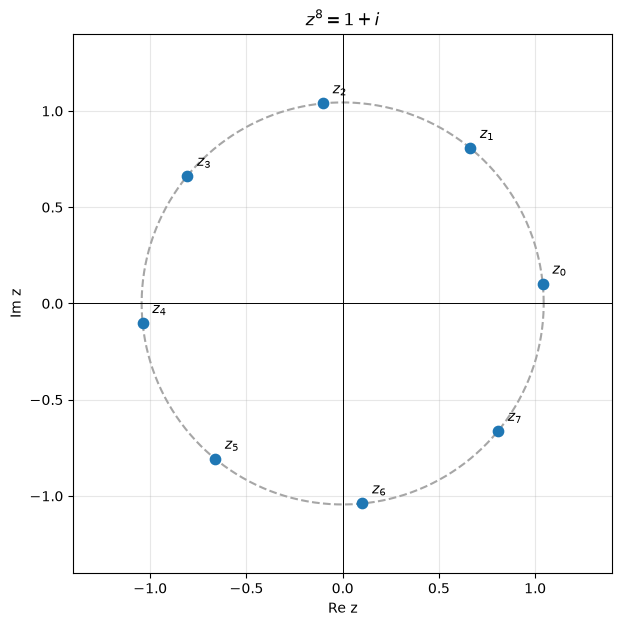

In [3]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display

# 2.2: 1+i = sqrt(2)*exp(i*pi/4).
k = sp.symbols('k', integer=True)
formula = 2**sp.Rational(1, 16)*sp.exp(sp.I*(sp.pi/32 + k*sp.pi/4))
print('2.2: z_k ='); display(formula)
print('k = 0, 1, ..., 7. Все 8 корней различны.')
roots = 2**(1/16)*np.exp(1j*(np.pi/32 + np.arange(8)*np.pi/4))
for j, z in enumerate(roots):
    print(f'z_{j} = {z.real:.10f} {z.imag:+.10f}i')

fig, ax = plt.subplots(figsize=(7, 7))
theta = np.linspace(0, 2*np.pi, 500)
ax.plot(2**(1/16)*np.cos(theta), 2**(1/16)*np.sin(theta), '--', color='0.65')
ax.scatter(roots.real, roots.imag, color='#1f77b4', s=55, zorder=3)
for j, z in enumerate(roots):
    ax.annotate(f'$z_{j}$', (z.real, z.imag), xytext=(7, 7), textcoords='offset points')
ax.axhline(0, color='black', lw=0.7); ax.axvline(0, color='black', lw=0.7)
ax.set(xlabel='Re z', ylabel='Im z', title=r'$z^8=1+i$', xlim=(-1.4, 1.4), ylim=(-1.4, 1.4))
ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.show()


## 2.3

2.3(a): подкоренное выражение = 1


k = 0, ..., 7

2.3(b): подкоренное выражение = -9/2 + 9*sqrt(3)*I/2


k = 0, ..., 3

2.3(c): подкоренное выражение = 9 - 8*I


k = 0, ..., 2

2.3(d): подкоренное выражение = 1 - I


k = 0, ..., 8



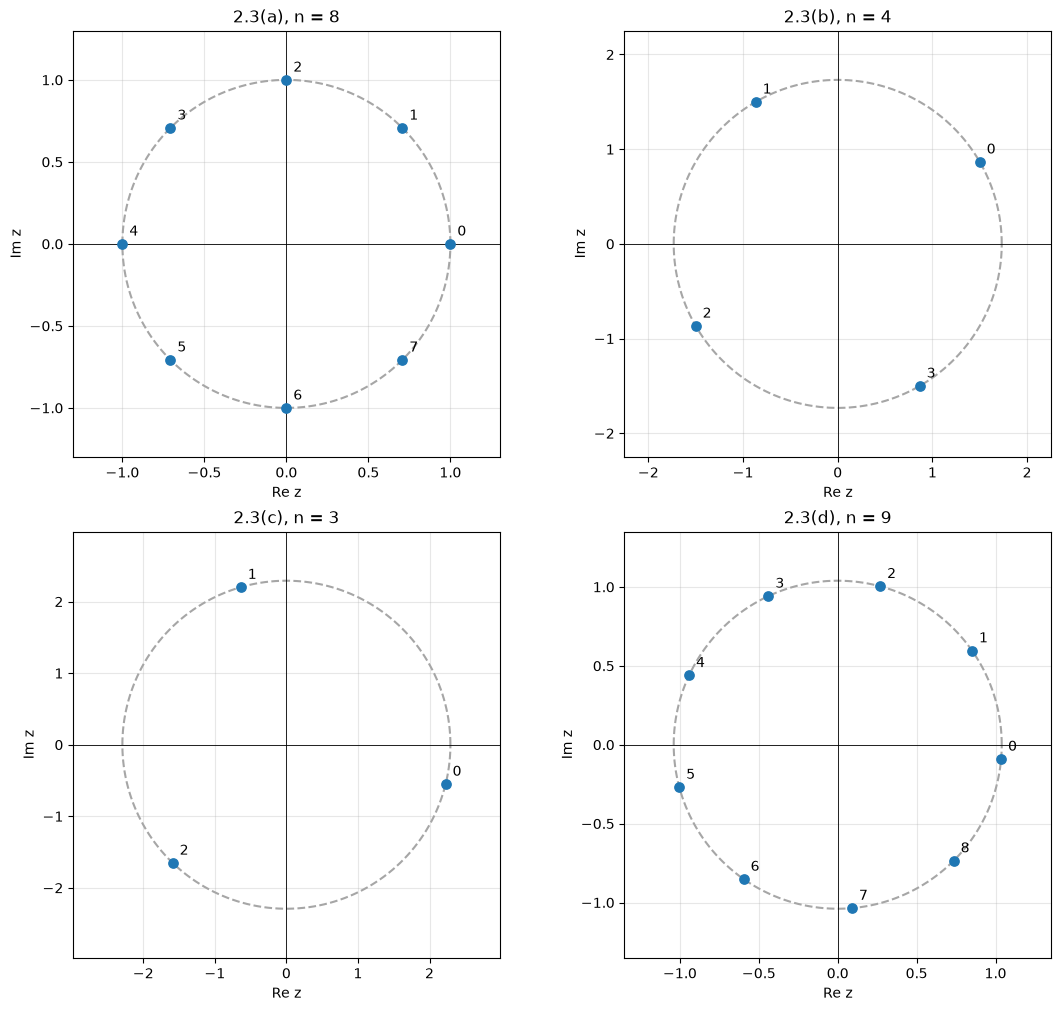

In [4]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display

# 2.3: у комплексного корня степени n учитываем все n значений.
radicands = [sp.Integer(1), -18/(1 + sp.I*sp.sqrt(3)),
             (1 - 5*sp.I)/(1 + sp.I) - 5*(1 + 2*sp.I)/(2 - sp.I) + 11,
             1 - sp.I]
degrees = [8, 4, 3, 9]
k = sp.symbols('k', integer=True)
fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for label, w, n, ax in zip('abcd', radicands, degrees, axes.flat):
    w = sp.simplify(sp.expand_complex(w))
    radius = sp.simplify(sp.Abs(w)**sp.Rational(1, n))
    angle = sp.arg(w)
    print(f'2.3({label}): подкоренное выражение = {w}')
    display(radius*sp.exp(sp.I*(angle + 2*sp.pi*k)/n))
    print(f'k = 0, ..., {n-1}\n')
    roots = float(radius)*np.exp(1j*(float(angle) + 2*np.pi*np.arange(n))/n)
    theta = np.linspace(0, 2*np.pi, 400)
    ax.plot(float(radius)*np.cos(theta), float(radius)*np.sin(theta), '--', color='0.65')
    ax.scatter(roots.real, roots.imag, s=45, zorder=3)
    for j, z in enumerate(roots):
        ax.annotate(str(j), (z.real, z.imag), xytext=(5, 6), textcoords='offset points')
    limit = 1.3*float(radius)
    ax.axhline(0, color='black', lw=0.6); ax.axvline(0, color='black', lw=0.6)
    ax.set(xlabel='Re z', ylabel='Im z', title=f'2.3({label}), n = {n}',
           xlim=(-limit, limit), ylim=(-limit, limit))
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.show()


## 2.4

2.4(a): x^2/3 + y^2/4 < 1, внутренняя область эллипса без границы.
2.4(b): x+y < sqrt(2), открытая полуплоскость.
2.4(c): y=0, x+y=0, поэтому единственная точка z=0.
2.4(d): (i-z)/(z+i) = (1-x^2-y^2+2ix)/(x^2+(y+1)^2).
         Ответ: x>0, x^2+y^2<1; открытый правый полукруг.
2.4(e): -2*pi/3 > -5*pi/6, поэтому ответ: пустое множество.
2.4(f): U=3x-x^2-y^2-y, V=x-3y-3.
         Ответ: V <= -sqrt(3)*|U|, кроме z=-i и z=3.
         Граничные дуги включены; обе точки их соединения исключены.


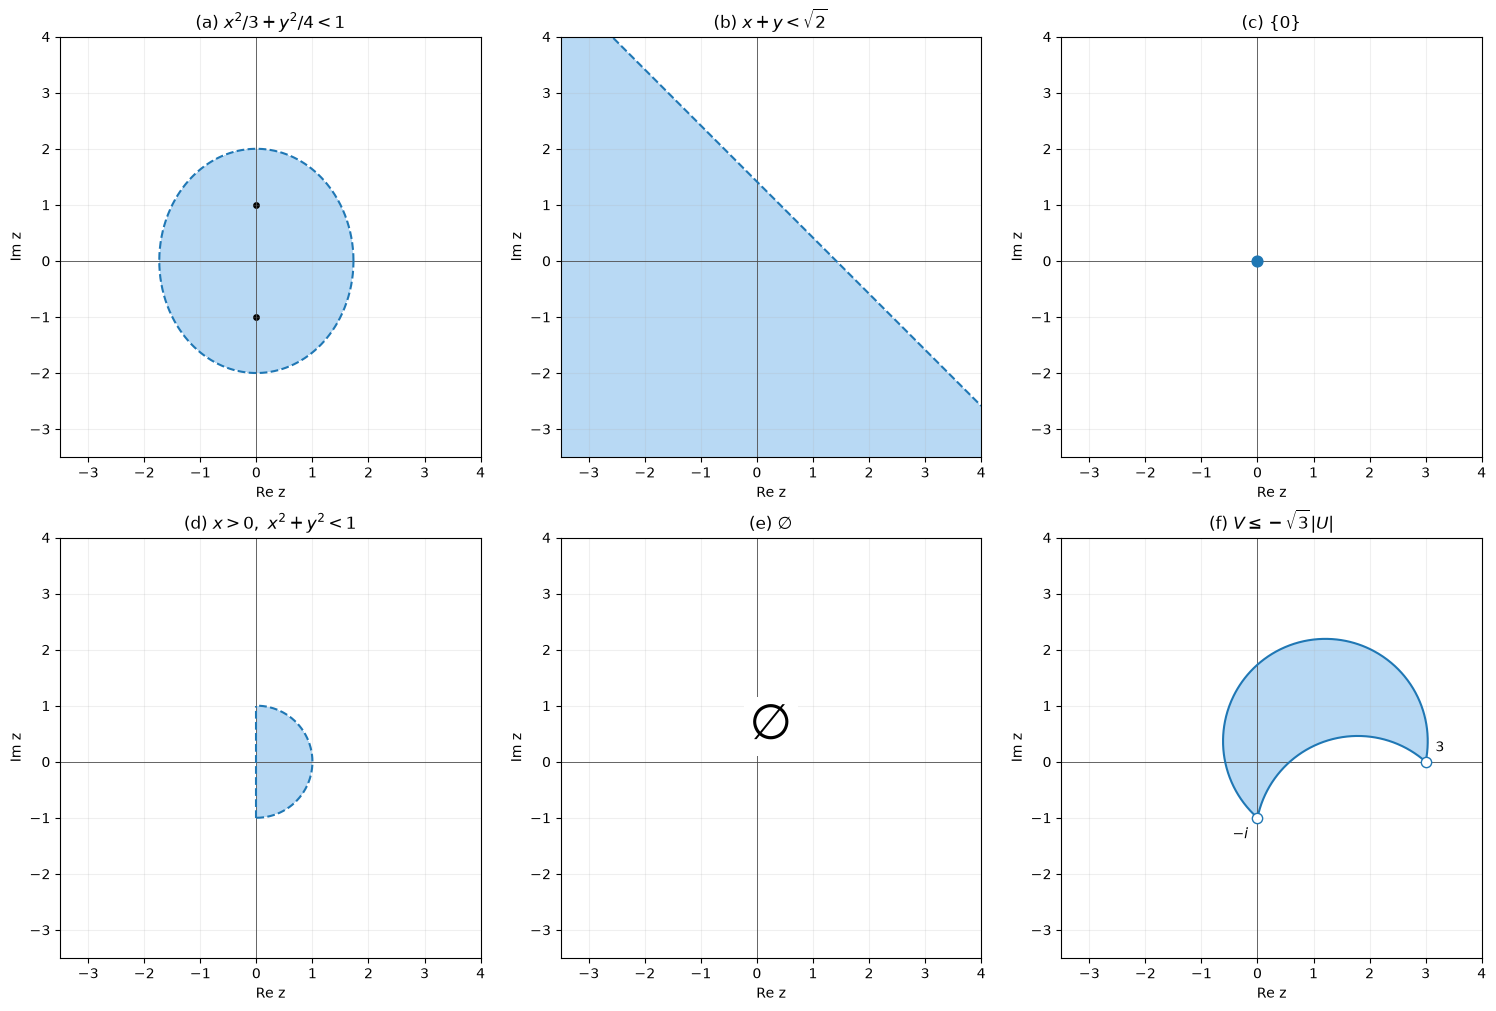

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 2.4: z=x+iy; главный аргумент выбираем в (-pi, pi].
print('2.4(a): x^2/3 + y^2/4 < 1, внутренняя область эллипса без границы.')
print('2.4(b): x+y < sqrt(2), открытая полуплоскость.')
print('2.4(c): y=0, x+y=0, поэтому единственная точка z=0.')
print('2.4(d): (i-z)/(z+i) = (1-x^2-y^2+2ix)/(x^2+(y+1)^2).')
print('         Ответ: x>0, x^2+y^2<1; открытый правый полукруг.')
print('2.4(e): -2*pi/3 > -5*pi/6, поэтому ответ: пустое множество.')
print('2.4(f): U=3x-x^2-y^2-y, V=x-3y-3.')
print('         Ответ: V <= -sqrt(3)*|U|, кроме z=-i и z=3.')
print('         Граничные дуги включены; обе точки их соединения исключены.')

grid = np.linspace(-3.5, 4, 1000)
X, Y = np.meshgrid(grid, grid)
U, V = 3*X-X**2-Y**2-Y, X-3*Y-3
masks = [X**2/3 + Y**2/4 < 1, X+Y < np.sqrt(2),
         np.zeros_like(X, dtype=bool), (X>0) & (X**2+Y**2<1),
         np.zeros_like(X, dtype=bool),
         (V <= -np.sqrt(3)*np.abs(U)) & (X**2+(Y+1)**2 > 1e-12)
         & ((X-3)**2+Y**2 > 1e-12)]
titles = [r'(a) $x^2/3+y^2/4<1$', r'(b) $x+y<\sqrt{2}$',
          r'(c) $\{0\}$', r'(d) $x>0,\ x^2+y^2<1$',
          r'(e) $\varnothing$', r'(f) $V\leq-\sqrt{3}|U|$']
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for ax, mask, title in zip(axes.flat, masks, titles):
    ax.imshow(mask, origin='lower', extent=[grid[0], grid[-1], grid[0], grid[-1]],
              cmap=ListedColormap(['white', '#b8d9f4']), interpolation='nearest', vmin=0, vmax=1)
    ax.axhline(0, color='0.3', lw=0.6); ax.axvline(0, color='0.3', lw=0.6)
    ax.set(xlabel='Re z', ylabel='Im z', title=title,
           xlim=(-3.5, 4), ylim=(-3.5, 4))
    ax.set_aspect('equal'); ax.grid(alpha=0.2)
theta = np.linspace(0, 2*np.pi, 600)
axes[0, 0].plot(np.sqrt(3)*np.cos(theta), 2*np.sin(theta), '--', color='#1f77b4')
axes[0, 0].scatter([0, 0], [-1, 1], color='black', s=15)
axes[0, 1].plot(grid, np.sqrt(2)-grid, '--', color='#1f77b4')
axes[0, 2].scatter([0], [0], color='#1f77b4', s=60, zorder=4)
t = np.linspace(-np.pi/2, np.pi/2, 500)
axes[1, 0].plot(np.cos(t), np.sin(t), '--', color='#1f77b4')
axes[1, 0].plot([0, 0], [-1, 1], '--', color='#1f77b4')
axes[1, 1].text(0.5, 0.55, r'$\varnothing$', transform=axes[1, 1].transAxes,
                fontsize=35, ha='center', va='center', bbox=dict(facecolor='white', edgecolor='none'))
r = np.geomspace(1e-6, 1e6, 2000)
for theta in [-2*np.pi/3, -np.pi/3]:
    w = r*np.exp(1j*theta)
    z = (3-1j*w)/(1+w)
    axes[1, 2].plot(z.real, z.imag, color='#1f77b4', lw=1.5)
axes[1, 2].scatter([0, 3], [-1, 0], facecolors='white', edgecolors='#1f77b4', s=55, zorder=5)
axes[1, 2].annotate('$-i$', (0, -1), xytext=(-18, -15), textcoords='offset points')
axes[1, 2].annotate('$3$', (3, 0), xytext=(7, 7), textcoords='offset points')
plt.show()


## 2.5

In [6]:
import sympy as sp
from IPython.display import display
sp.init_printing()

# 2.5: A|z|^2 + conjugate(B)*z + B*conjugate(z) + C = 0.
A = sp.symbols('A', positive=True)
C, x, y, u, v = sp.symbols('C x y u v', real=True)
z, B = x+sp.I*y, u+sp.I*v
original = sp.expand(A*z*sp.conjugate(z) + sp.conjugate(B)*z + B*sp.conjugate(z) + C)
completed = A*((x+u/A)**2 + (y+v/A)**2) + C - (u**2+v**2)/A
print('2.5: выделим полный квадрат:')
print('A*|z+B/A|^2 + C - |B|^2/A = 0.')
print('Тождество проверено:', sp.simplify(original-completed) == 0)
print('Следовательно, |z+B/A|^2 = (|B|^2-AC)/A^2.')
print('При AC<|B|^2 и A>0 правая часть положительна: это окружность.')
print('Центр z_0 = -B/A, в координатах:'); display((-u/A, -v/A))
print('Радиус R = sqrt(|B|^2-AC)/A:'); display(sp.sqrt(u**2+v**2-A*C)/A)


2.5: выделим полный квадрат:
A*|z+B/A|^2 + C - |B|^2/A = 0.
Тождество проверено: True
Следовательно, |z+B/A|^2 = (|B|^2-AC)/A^2.
При AC<|B|^2 и A>0 правая часть положительна: это окружность.
Центр z_0 = -B/A, в координатах:


Радиус R = sqrt(|B|^2-AC)/A:


## 2.6

In [7]:
import sympy as sp
from IPython.display import display

# 2.6: вычисление всех корней с 40 значащими цифрами.
x = sp.symbols('x')
p = x**11 + x**10 + x**8 - 2*x**7 - x**5 + x**4 + 2*x**2 + 2*x + 2
roots = sorted(sp.nroots(p, n=40, maxsteps=200),
               key=lambda z: (float(sp.re(z)), float(sp.im(z))))
print('2.6: все 11 корней:')
for j, z in enumerate(roots, 1):
    print(f'z_{j:2d} = {float(sp.re(z)):.12f} {float(sp.im(z)):+.12f}i')
sum_abs = sp.N(sum(sp.Abs(z) for z in roots), 20)
max_real = max(sp.re(z) for z in roots)
print('\n1) Сумма модулей =', sum_abs)
print('2) Максимальная действительная часть =', sp.N(max_real, 20))
residual = max(abs(complex(sp.N(p.subs(x, z), 30))) for z in roots)
print(f'Максимальная невязка |p(z_j)| = {residual:.2e}')


2.6: все 11 корней:
z_ 1 = -1.776769024921 +0.000000000000i
z_ 2 = -0.707434455212 -0.464374725865i
z_ 3 = -0.707434455212 +0.464374725865i
z_ 4 = -0.450037112743 -0.803923144248i
z_ 5 = -0.450037112743 +0.803923144248i
z_ 6 = -0.012500180565 -1.182699081746i
z_ 7 = -0.012500180565 +1.182699081746i
z_ 8 = 0.477754523623 -0.901075230538i
z_ 9 = 0.477754523623 +0.901075230538i
z_10 = 1.080601737358 -0.323893118840i
z_11 = 1.080601737358 +0.323893118840i

1) Сумма модулей = 11.973384469712120146
2) Максимальная действительная часть = 1.0806017373578453121
Максимальная невязка |p(z_j)| = 1.41e-38


## 2.7

2.7(a): C_(1+i)^(1-i) = (4.36744914064013897 + 4.85162976515781154j)
2.7(b): Arg = 0.837869369550042 рад = 48.0063786585045 град.


2.7(c): шаг уровней pi/6; цвет показывает главный аргумент.
В точке z=0 выражение не определено; малая окрестность скрыта для читаемости.


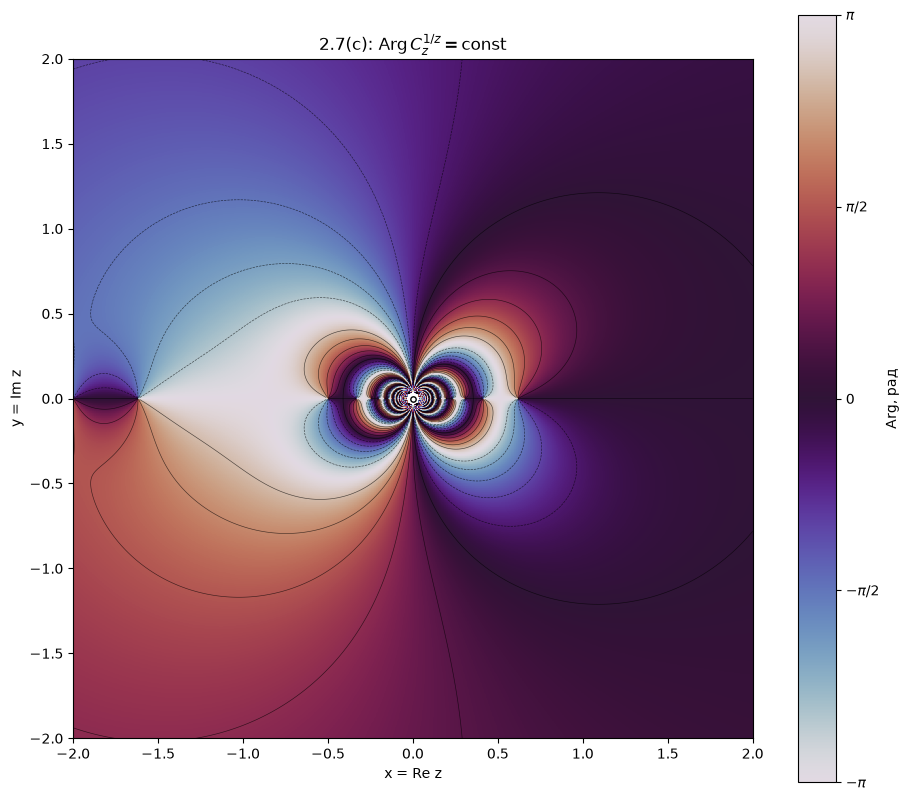

In [8]:
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.special import loggamma

# 2.7(a,b): C_z^w = Gamma(z+1)/(Gamma(w+1)*Gamma(z-w+1)).
with mp.workdps(40):
    z, w = mp.mpc(1, 1), mp.mpc(1, -1)
    value = mp.gamma(z+1)/(mp.gamma(w+1)*mp.gamma(z-w+1))
    argument = mp.arg(value)
    print('2.7(a): C_(1+i)^(1-i) =', mp.nstr(value, 18))
    print('2.7(b): Arg =', mp.nstr(argument, 15), 'рад =',
          mp.nstr(mp.degrees(argument), 15), 'град.')

# 2.7(c): линии уровня Arg(C_z^(1/z)); z=0 исключается.
# loggamma позволяет вычислять фазу без переполнения самих Gamma-функций.
x = np.linspace(-2, 2, 1000)
y = np.linspace(-2, 2, 1000)
X, Y = np.meshgrid(x, y)
Z = X+1j*Y
with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
    L = loggamma(Z+1) - loggamma(1/Z+1) - loggamma(Z-1/Z+1)
    phase = np.angle(np.exp(1j*L.imag))
phase[~np.isfinite(L) | (np.abs(Z) < 0.035)] = np.nan

# Не соединяем контуром точки по разные стороны скачка главного аргумента.
cut = np.zeros_like(phase, dtype=bool)
jump_x = np.abs(np.diff(phase, axis=1)) > np.pi
jump_y = np.abs(np.diff(phase, axis=0)) > np.pi
cut[:, :-1] |= jump_x; cut[:, 1:] |= jump_x
cut[:-1, :] |= jump_y; cut[1:, :] |= jump_y
contours = np.ma.masked_where(cut | ~np.isfinite(phase), phase)
fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
image = ax.imshow(phase, origin='lower', extent=[-2, 2, -2, 2],
                  cmap='twilight', vmin=-np.pi, vmax=np.pi, interpolation='nearest')
levels = np.arange(-5, 6)*np.pi/6
ax.contour(X, Y, contours, levels=levels, colors='black', linewidths=0.45, alpha=0.65)
ax.scatter([0], [0], facecolors='white', edgecolors='black', s=15, zorder=3)
ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
bar = fig.colorbar(image, ax=ax, ticks=ticks, label='Arg, рад')
bar.ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'])
ax.set(xlabel='x = Re z', ylabel='y = Im z',
       title=r'2.7(c): $\mathrm{Arg}\,C_z^{1/z}=\mathrm{const}$')
ax.set_aspect('equal')
print('2.7(c): шаг уровней pi/6; цвет показывает главный аргумент.')
print('В точке z=0 выражение не определено; малая окрестность скрыта для читаемости.')
plt.show()


## 2.8

In [9]:
import sympy as sp
from IPython.display import display

# 2.8: корни из единицы exp(2*pi*i*k/14).
# При Im(lambda)>0 максимальный Re(lambda) достигается при k=1.
lam = sp.exp(sp.I*sp.pi/7)
A = sp.Matrix([[7, 5], [6, 2]])
determinant = sp.expand((A+lam*sp.eye(2)).det())
real_part = -16 + 9*sp.cos(sp.pi/7) + sp.cos(2*sp.pi/7)
imag_part = 9*sp.sin(sp.pi/7) + sp.sin(2*sp.pi/7)
print('2.8: lambda ='); display(lam)
print('det(A+lambda*I) = lambda^2+9*lambda-16 ='); display(determinant)
print('1) Действительная часть:'); display(real_part)
print('Re =', sp.N(real_part, 16))
print('2) Мнимая часть:'); display(imag_part)
print('Im =', sp.N(imag_part, 16))


2.8: lambda =


det(A+lambda*I) = lambda^2+9*lambda-16 =


1) Действительная часть:


Re = -7.267790387019494
2) Мнимая часть:


Im = 4.686785134526053


## 2.9

2.9(a,b): множество Жюлиа описывает неустойчивую динамику итераций.
Для z^2+c оно является границей заполненного множества Жюлиа,
состоящего из точек с ограниченной последовательностью итераций.


2.9(c): цвет показывает время выхода; чёрный цвет означает,
что за 1000 итераций выхода не обнаружено. Множество Жюлиа лежит на границе.


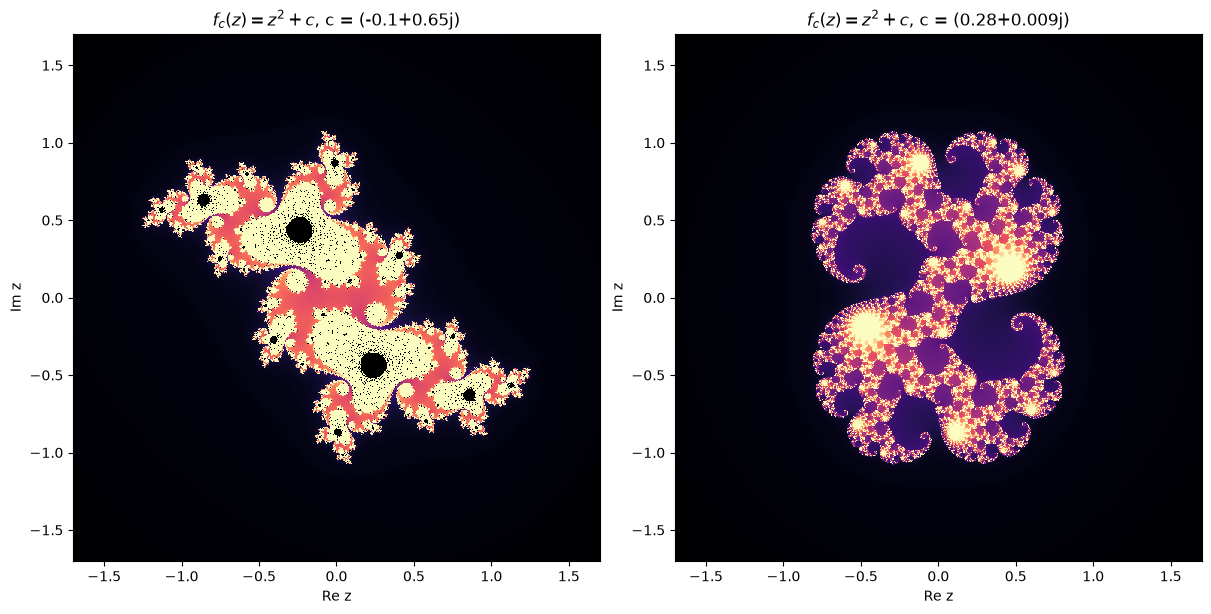

2.9(d): численные приближения множеств Жюлиа обратными итерациями.
Первые 150 шагов отброшены; использовано 1 000 000 точек для каждой функции.
Цвет показывает плотность полученных точек; результат воспроизводим (seed задан).


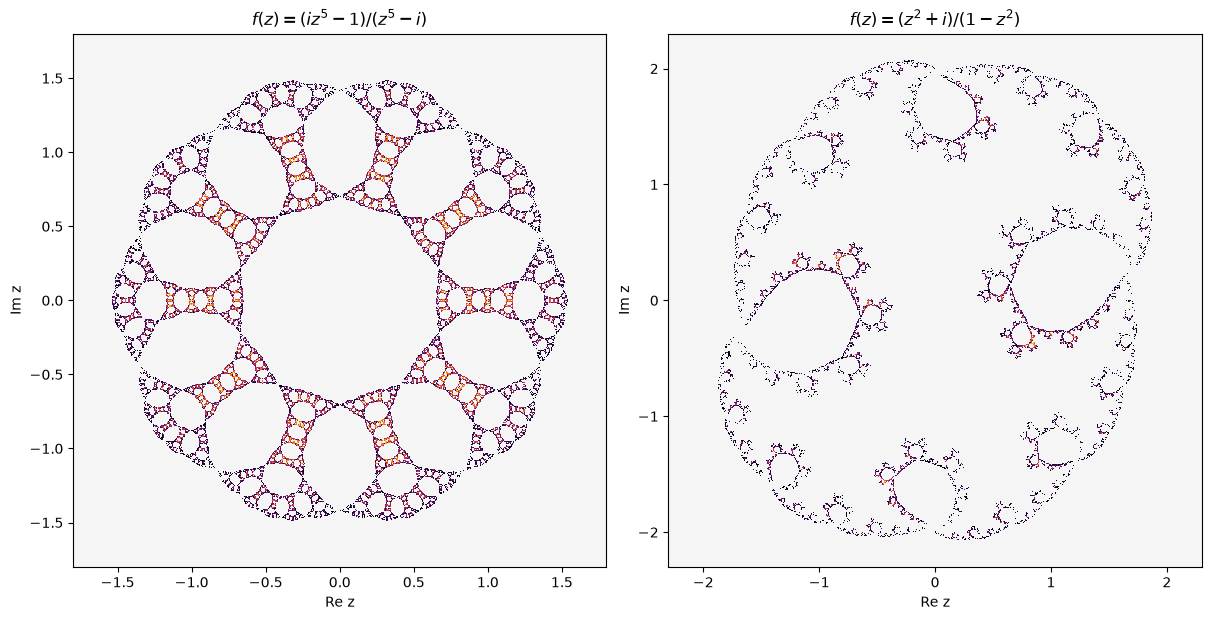

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 2.9(a,b): материалы из условия:
# https://ru.wikipedia.org/wiki/Множество_Жюлиа
# https://blbadger.github.io/julia-sets#julia-sets-are-fractals
print('2.9(a,b): множество Жюлиа описывает неустойчивую динамику итераций.')
print('Для z^2+c оно является границей заполненного множества Жюлиа,')
print('состоящего из точек с ограниченной последовательностью итераций.')

# 2.9(c): векторизованный алгоритм времени выхода.
# Для данных |c|<2 условие |z|>2 гарантирует уход к бесконечности.
def polynomial_julia(c, size=700, max_iter=1000, limit=1.7):
    x = np.linspace(-limit, limit, size)
    y = np.linspace(-limit, limit, size)
    z = x[None, :] + 1j*y[:, None]
    active = np.abs(z) <= 2
    escape = np.zeros(z.shape, dtype=float)
    escape[active] = max_iter
    for n in range(max_iter):
        if not np.any(active):
            break
        z[active] = z[active]**2+c
        left = active & (np.abs(z)>2)
        # Сглаживание полос времени выхода.
        escape[left] = n+2-np.log2(np.log(np.abs(z[left])))
        active[left] = False
    return escape, (-limit, limit, -limit, limit)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
cmap = plt.get_cmap('magma').copy(); cmap.set_bad('black')
for ax, c in zip(axes, [-0.1+0.65j, 0.28+0.009j]):
    values, extent = polynomial_julia(c)
    ax.imshow(np.ma.masked_where(values>=1000, values), extent=extent, origin='lower', cmap=cmap,
              vmin=0, vmax=120, interpolation='nearest')
    ax.set(xlabel='Re z', ylabel='Im z', title=f'$f_c(z)=z^2+c$, c = {c}')
    ax.set_aspect('equal')
print('2.9(c): цвет показывает время выхода; чёрный цвет означает,')
print('что за 1000 итераций выхода не обнаружено. Множество Жюлиа лежит на границе.')
plt.show()

# 2.9(d): для рациональных функций используем обратные итерации.
# Из w=(i*z^5-1)/(z^5-i) получаем z^5=(i*w-1)/(w-i).
# Из w=(z^2+i)/(1-z^2) получаем z^2=(w-i)/(w+1).
# На каждом шаге равновероятно выбирается одна из d обратных ветвей.
def rational_julia(degree, inverse_power, seed, walkers=5000,
                   warmup=150, steps=200):
    rng = np.random.default_rng(seed)
    w = rng.uniform(-1, 1, walkers) + 1j*rng.uniform(-1, 1, walkers)
    samples = []
    for n in range(warmup+steps):
        q = inverse_power(w)
        branch = rng.integers(0, degree, walkers)
        w = np.abs(q)**(1/degree)*np.exp(1j*(np.angle(q)+2*np.pi*branch)/degree)
        if n >= warmup:
            samples.append(w.copy())
    return np.concatenate(samples)

functions = [
    (5, lambda w: (1j*w-1)/(w-1j), r'$f(z)=(iz^5-1)/(z^5-i)$', 2091, 1.8),
    (2, lambda w: (w-1j)/(w+1), r'$f(z)=(z^2+i)/(1-z^2)$', 2092, 2.3)
]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, (degree, inverse_power, title, seed, limit) in zip(axes, functions):
    samples = rational_julia(degree, inverse_power, seed)
    density, xedges, yedges = np.histogram2d(samples.real, samples.imag, bins=900,
                                            range=[[-limit, limit], [-limit, limit]])
    ax.imshow(np.ma.masked_equal(density.T, 0), origin='lower',
              extent=[-limit, limit, -limit, limit], cmap='inferno',
              norm=LogNorm(vmin=1, vmax=max(2, density.max())), interpolation='nearest')
    ax.set_facecolor('#f5f5f5')
    ax.set(xlabel='Re z', ylabel='Im z', title=title)
    ax.set_aspect('equal')
print('2.9(d): численные приближения множеств Жюлиа обратными итерациями.')
print('Первые 150 шагов отброшены; использовано 1 000 000 точек для каждой функции.')
print('Цвет показывает плотность полученных точек; результат воспроизводим (seed задан).')
plt.show()


## 2.10

2.10: X=4x/(x^2+y^2+4), Y=4y/(x^2+y^2+4), H=2(x^2+y^2)/(x^2+y^2+4).
Тогда X^2+Y^2+(H-1)^2=1; точке бесконечности соответствует N=(0,0,2).
Синим показаны исходные кривые на плоскости, красным - их образы на сфере.
Выбраны: y=0.8; |z-(0.5+0.4i)|=1.3; y=0.6x^2; x^2-y^2=1.


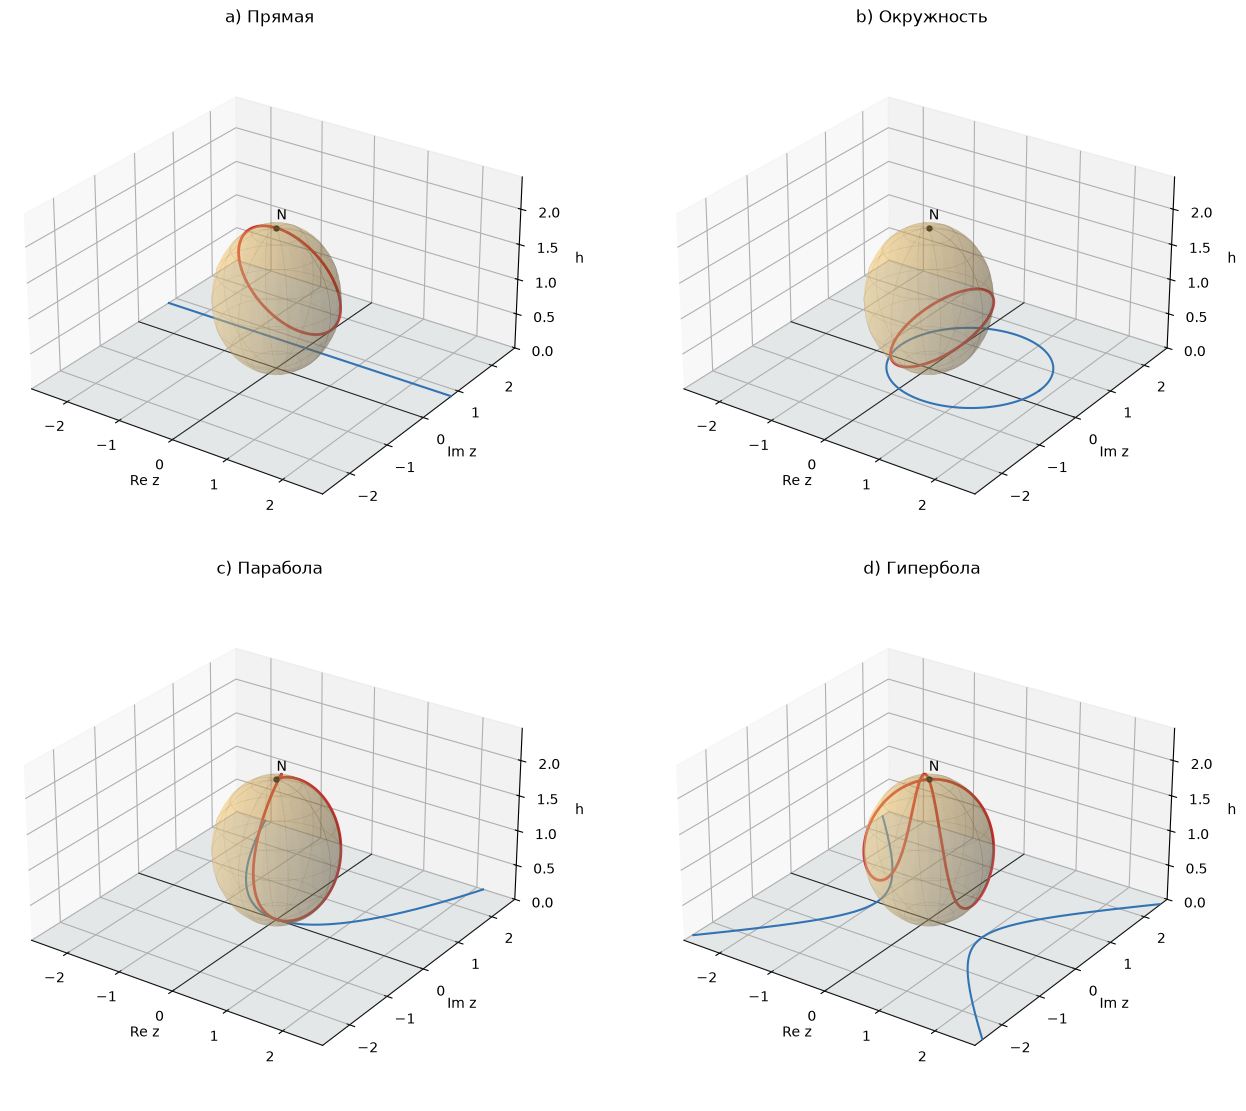

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 2.10: сфера радиуса 1 с центром (0,0,1), комплексная плоскость h=0.
# Стереографическая проекция из северного полюса N=(0,0,2).
def stereographic(z):
    r2 = z.real**2 + z.imag**2
    return 4*z.real/(r2+4), 4*z.imag/(r2+4), 2*r2/(r2+4)

def draw_sphere(ax):
    u = np.linspace(0, 2*np.pi, 65)
    v = np.linspace(0, np.pi, 33)
    sx = np.outer(np.cos(u), np.sin(v))
    sy = np.outer(np.sin(u), np.sin(v))
    sh = 1+np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(sx, sy, sh, color='#ffcc66', alpha=0.30, linewidth=0)
    ax.plot_wireframe(sx, sy, sh, rstride=8, cstride=4, color='0.4', alpha=0.30, linewidth=0.4)
    plane = np.linspace(-2.7, 2.7, 2)
    px, py = np.meshgrid(plane, plane)
    ax.plot_surface(px, py, np.zeros_like(px), color='#d5e4f0', alpha=0.20)
    ax.plot([-2.7, 2.7], [0, 0], [0, 0], color='black', lw=0.7)
    ax.plot([0, 0], [-2.7, 2.7], [0, 0], color='black', lw=0.7)
    ax.scatter([0], [0], [2], s=12, color='black')
    ax.text(0, 0, 2.12, 'N')
    ax.set(xlim=(-2.7, 2.7), ylim=(-2.7, 2.7), zlim=(0, 2.45),
           xlabel='Re z', ylabel='Im z', zlabel='h')
    ax.set_box_aspect((1, 1, 0.55)); ax.view_init(elev=27, azim=-55)

print('2.10: X=4x/(x^2+y^2+4), Y=4y/(x^2+y^2+4), H=2(x^2+y^2)/(x^2+y^2+4).')
print('Тогда X^2+Y^2+(H-1)^2=1; точке бесконечности соответствует N=(0,0,2).')
print('Синим показаны исходные кривые на плоскости, красным - их образы на сфере.')
print('Выбраны: y=0.8; |z-(0.5+0.4i)|=1.3; y=0.6x^2; x^2-y^2=1.')
t = np.tan(np.linspace(-np.pi/2+1e-5, np.pi/2-1e-5, 6000))
theta = np.linspace(0, 2*np.pi, 1500)
s = np.linspace(-11, 11, 3500)
curves = [
    ('a) Прямая', [t+0.8j]),
    ('b) Окружность', [0.5+0.4j+1.3*np.exp(1j*theta)]),
    ('c) Парабола', [t+0.6j*t**2]),
    ('d) Гипербола', [np.cosh(s)+1j*np.sinh(s), -np.cosh(s)+1j*np.sinh(s)])
]
fig = plt.figure(figsize=(13, 11), layout='constrained')
for index, (title, branches) in enumerate(curves, 1):
    ax = fig.add_subplot(2, 2, index, projection='3d')
    draw_sphere(ax)
    for z in branches:
        visible = (np.abs(z.real)<2.7) & (np.abs(z.imag)<2.7)
        plane_z = np.where(visible, z, np.nan+1j*np.nan)
        ax.plot(plane_z.real, plane_z.imag, np.zeros(z.size), color='#1765b2', lw=1.5)
        ax.plot(*stereographic(z), color='#d62728', lw=2)
    ax.set_title(title)
plt.show()


## 2.10

2.10 (спираль): r=a*exp(b*phi), a=0.7, b=0.16.
X=4a*exp(b*phi)*cos(phi)/(a^2*exp(2b*phi)+4),
Y=4a*exp(b*phi)*sin(phi)/(a^2*exp(2b*phi)+4),
H=2a^2*exp(2b*phi)/(a^2*exp(2b*phi)+4).
При phi -> -infinity образ стремится к южному полюсу (0,0,0),
при phi -> +infinity - к северному полюсу (0,0,2).


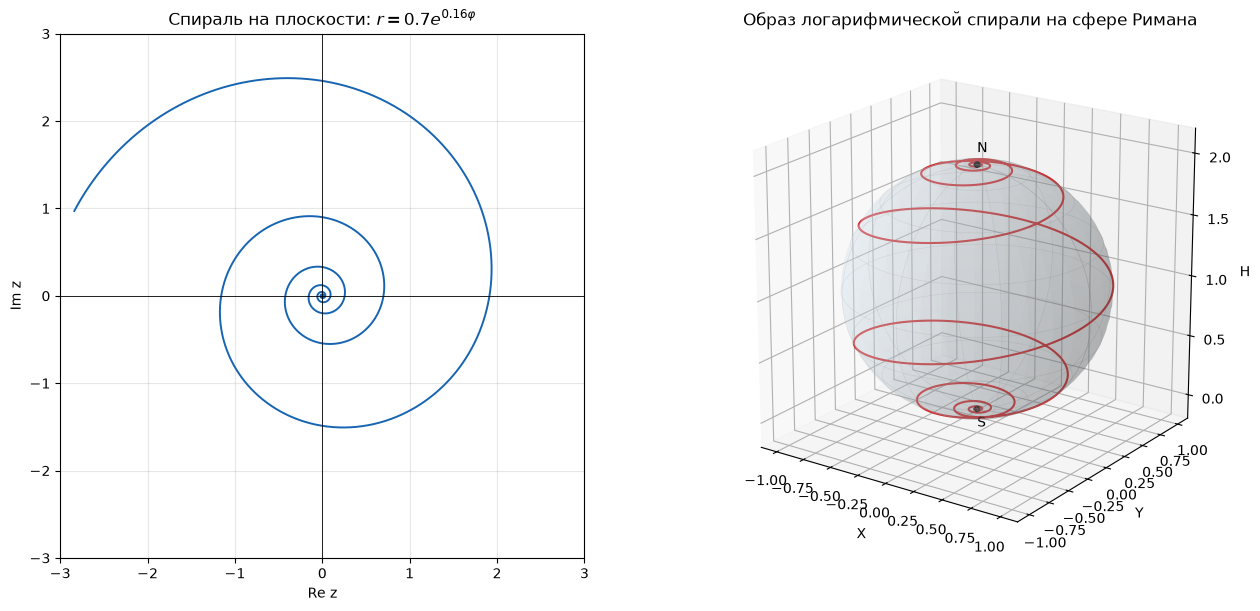

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Второе задание 2.10 в исходном листке; a и b можно менять.
a, b = 0.7, 0.16
phi = np.linspace(-16*np.pi, 16*np.pi, 14000)
r = a*np.exp(b*phi)
z = r*np.exp(1j*phi)
r2 = r**2
X = 4*z.real/(r2+4)
Y = 4*z.imag/(r2+4)
H = 2*r2/(r2+4)
print(f'2.10 (спираль): r=a*exp(b*phi), a={a}, b={b}.')
print('X=4a*exp(b*phi)*cos(phi)/(a^2*exp(2b*phi)+4),')
print('Y=4a*exp(b*phi)*sin(phi)/(a^2*exp(2b*phi)+4),')
print('H=2a^2*exp(2b*phi)/(a^2*exp(2b*phi)+4).')
print('При phi -> -infinity образ стремится к южному полюсу (0,0,0),')
print('при phi -> +infinity - к северному полюсу (0,0,2).')

fig = plt.figure(figsize=(13, 6), layout='constrained')
ax1 = fig.add_subplot(1, 2, 1)
# Для читаемости на плоскости показываем часть спирали с r<=3.
visible = r<=3
ax1.plot(z.real[visible], z.imag[visible], color='#1765b2', lw=1.4)
ax1.axhline(0, color='black', lw=0.6); ax1.axvline(0, color='black', lw=0.6)
ax1.set(xlabel='Re z', ylabel='Im z', xlim=(-3, 3), ylim=(-3, 3),
        title=rf'Спираль на плоскости: $r={a}e^{{{b}\varphi}}$')
ax1.set_aspect('equal'); ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
u = np.linspace(0, 2*np.pi, 65)
v = np.linspace(0, np.pi, 33)
sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sh = 1+np.outer(np.ones_like(u), np.cos(v))
ax2.plot_surface(sx, sy, sh, color='#d5e4f0', alpha=0.22, linewidth=0)
ax2.plot_wireframe(sx, sy, sh, rstride=8, cstride=4, color='0.6', alpha=0.3, linewidth=0.4)
ax2.plot(X, Y, H, color='#d62728', lw=1.5)
ax2.scatter([0, 0], [0, 0], [0, 2], color='black', s=15)
ax2.text(0, 0, 2.1, 'N'); ax2.text(0, 0, -0.15, 'S')
ax2.set(xlabel='X', ylabel='Y', zlabel='H', zlim=(-0.2, 2.2),
        title='Образ логарифмической спирали на сфере Римана')
ax2.set_box_aspect((1, 1, 1)); ax2.view_init(elev=20, azim=-55)
plt.show()
